# AI-Based Digital Learning Assistant
## Baseline Model: Logistic Regression on Engineered Features

- **Project:** Student Correctness Prediction (Binary Classification)
- **Dataset:** ASSISTments Skill Builder (525,534 student interaction records)
- **Feature Set:** 11 hypothesis-driven features from `data/processed/engineered_features.csv`
- **Model:** Standardized Logistic Regression Pipeline (`StandardScaler` + `LogisticRegression`)
- **Tracking:** MLflow on DAGsHub (`https://dagshub.com/suhaybfr/ML-ops.mlflow`)


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
import mlflow
import mlflow.sklearn


2026/10/14 02:38:57 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at D:\btech\projects\mlops\.venv\lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


### 1. Load Processed Feature Matrix
We load the version-controlled `engineered_features.csv` generated during data preprocessing.


In [ ]:
data_path = '../data/processed/engineered_features.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape}")
print(f"Total Student Interactions: {len(df):,}")
df.head()


Dataset Shape: (525534, 17)
Total Student Interactions: 525,534


,user_id,problem_id,skill_name,opportunity,log_opportunity,attempt_count,hint_count,bottom_hint,hint_ratio,first_try_correct,user_prev_acc,problem_difficulty,skill_difficulty,is_skill_unmapped,log_response_time,is_rapid_guess,correct
0,14,93383,Circle Graph,1,0.693147,1,2,1,1.0,0,0.00,0.416667,0.523196,0,10.176259,0,0
1,14,93383,Unknown,1,0.693147,1,2,1,1.0,0,0.00,0.416667,0.590227,1,10.176259,0,0
2,14,93383,Percent Of,1,0.693147,1,2,1,1.0,0,0.00,0.416667,0.711482,0,10.176259,0,0
3,14,93407,Circle Graph,2,1.098612,1,0,0,0.0,1,0.00,0.379310,0.523196,0,10.279318,0,1
4,14,93407,Unknown,2,1.098612,1,0,0,0.0,1,0.25,0.379310,0.590227,1,10.279318,0,1


In [ ]:
target_dist = df['correct'].value_counts(normalize=True) * 100
print("Target Class Distribution:")
print(f"  Class 1 (Correct on First Try): {target_dist[1]:.2f}%")
print(f"  Class 0 (Incorrect / Needed Hints): {target_dist[0]:.2f}%")


Target Class Distribution:
  Class 1 (Correct on First Try): 67.95%
  Class 0 (Incorrect / Needed Hints): 32.05%


### 2. Feature Selection & Preventing Target Leakage
- **Excluded Columns:**
  - `user_id`, `problem_id`, `skill_name`: Categorical entity identifiers.
  - `first_try_correct`: Excluded because it explicitly incorporates the target label (`correct == 1`). Including it would cause **data leakage**.
- **Selected Predictor Features (11 features):**
  1. `log_opportunity`: Practice volume (learning curve).
  2. `attempt_count`: Interactions on current problem.
  3. `hint_count`: Hints requested.
  4. `bottom_hint`: Binary indicator if bottom hint was viewed.
  5. `hint_ratio`: Ratio of hints used to total hints available.
  6. `user_prev_acc`: Prior cumulative accuracy (lagged expanding mean).
  7. `problem_difficulty`: Target-encoded pass rate for the problem.
  8. `skill_difficulty`: Target-encoded pass rate for the skill domain.
  9. `is_skill_unmapped`: Binary flag for untagged/scaffolded problems.
  10. `log_response_time`: Response latency in log scale.
  11. `is_rapid_guess`: Binary flag for response under 3 seconds.


In [ ]:
features = [
    'log_opportunity',
    'attempt_count',
    'hint_count',
    'bottom_hint',
    'hint_ratio',
    'user_prev_acc',
    'problem_difficulty',
    'skill_difficulty',
    'is_skill_unmapped',
    'log_response_time',
    'is_rapid_guess'
]
target = 'correct'

# Drop rows with nulls in features (if any)
df_clean = df.dropna(subset=features + [target]).copy()

X = df_clean[features]
y = df_clean[target]

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape:   {y.shape}")


Feature matrix X shape: (525534, 11)
Target vector y shape:   (525534,)


### 3. Stratified Train-Test Split (80/20)
Preserves class balance across both partitions.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set:   {len(X_train):,} samples")
print(f"Testing set:    {len(X_test):,} samples")


Training set:   420,427 samples
Testing set:    105,107 samples


### 4. Build Pipeline & Train Model
Standardizes features using `StandardScaler` so that:
- Gradient optimization converges quickly.
- Feature coefficients are directly comparable to evaluate relative feature importance.


In [ ]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        solver='lbfgs',
        class_weight='balanced'
    ))
])

print("Training Logistic Regression pipeline...")
pipeline.fit(X_train, y_train)
print("Training completed successfully!")


Training Logistic Regression pipeline...


Training completed successfully!


### 5. Model Evaluation Metrics


In [ ]:
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("=" * 45)
print("     BASELINE LOGISTIC REGRESSION RESULTS")
print("=" * 45)
print(f"  Accuracy:   {acc:.4f}  ({acc * 100:.2f}%)")
print(f"  Precision:  {prec:.4f}  ({prec * 100:.2f}%)")
print(f"  Recall:     {rec:.4f}  ({rec * 100:.2f}%)")
print(f"  F1-Score:   {f1:.4f}  ({f1 * 100:.2f}%)")
print(f"  ROC-AUC:    {roc_auc:.4f}  ({roc_auc * 100:.2f}%)")
print("=" * 45)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))


     BASELINE LOGISTIC REGRESSION RESULTS
  Accuracy:   0.8881  (88.81%)
  Precision:  0.9159  (91.59%)
  Recall:     0.9198  (91.98%)
  F1-Score:   0.9178  (91.78%)
  ROC-AUC:    0.9378  (93.78%)

Classification Report:
              precision    recall  f1-score   support

           0     0.8285    0.8210    0.8247     33690
           1     0.9159    0.9198    0.9178     71417

    accuracy                         0.8881    105107
   macro avg     0.8722    0.8704    0.8713    105107
weighted avg     0.8879    0.8881    0.8880    105107



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print(f"  True Negatives (Correctly predicted failure):  {cm[0, 0]:,}")
print(f"  False Positives (Predicted pass, actually failed): {cm[0, 1]:,}")
print(f"  False Negatives (Predicted fail, actually passed): {cm[1, 0]:,}")
print(f"  True Positives (Correctly predicted pass):     {cm[1, 1]:,}")


Confusion Matrix:
[[27658  6032]
 [ 5727 65690]]
  True Negatives (Correctly predicted failure):  27,658
  False Positives (Predicted pass, actually failed): 6,032
  False Negatives (Predicted fail, actually passed): 5,727
  True Positives (Correctly predicted pass):     65,690


### 6. Interpretability: Standardized Feature Coefficients & Odds Ratios
In Logistic Regression, the exponentiated coefficient $\exp(\beta)$ represents the **Odds Ratio**:
- $\text{Odds Ratio} > 1$: Feature increases likelihood of student solving problem correctly.
- $\text{Odds Ratio} < 1$: Feature decreases likelihood of student solving problem correctly.


In [ ]:
clf = pipeline.named_steps['classifier']
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': clf.coef_[0],
    'Odds_Ratio': np.exp(clf.coef_[0])
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

coef_df


,Feature,Coefficient,Odds_Ratio
0,problem_difficulty,1.194241,3.301053e+00
1,user_prev_acc,0.628504,1.874804e+00
2,is_skill_unmapped,0.395638,1.485331e+00
3,log_opportunity,0.270046,1.310025e+00
4,skill_difficulty,0.075446,1.078365e+00
5,log_response_time,-0.070746,9.316981e-01
6,is_rapid_guess,-0.538902,5.833882e-01
7,hint_count,-2.225542,1.080089e-01
8,hint_ratio,-2.862280,5.713835e-02
9,bottom_hint,-6.455746,1.571466e-03


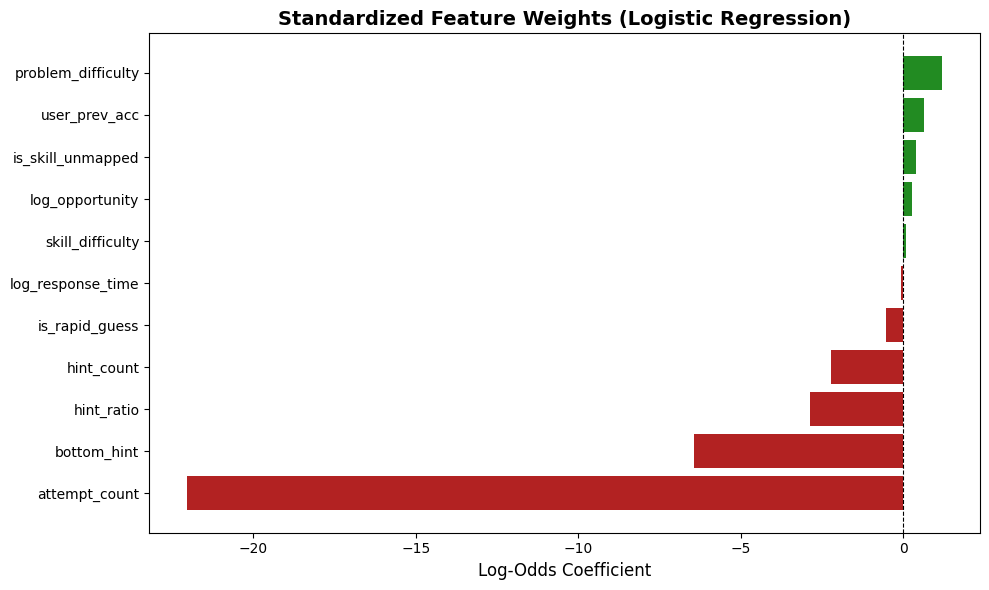

In [ ]:
plt.figure(figsize=(10, 6))
colors = ['forestgreen' if c > 0 else 'firebrick' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Standardized Feature Weights (Logistic Regression)', fontsize=14, fontweight='bold')
plt.xlabel('Log-Odds Coefficient', fontsize=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### 7. Experiment Tracking with MLflow on DAGsHub
Log the baseline experiment parameters, metrics, and serialized model artifact to DAGsHub.


In [ ]:
# Connect to DAGsHub MLflow (credentials loaded from .dvc/config.local or env)
import sys
sys.path.append('../src')
from utils import setup_mlflow
tracking_uri = setup_mlflow(experiment_name='student_performance_baseline')

with mlflow.start_run(run_name='logistic_regression_baseline'):
    # Log parameters
    mlflow.log_params({
        'model_type': 'LogisticRegression',
        'solver': 'lbfgs',
        'max_iter': 1000,
        'features_count': len(features),
        'train_samples': len(X_train),
        'test_samples': len(X_test),
        'features': ', '.join(features)
    })
    
    # Log metrics
    mlflow.log_metrics({
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1,
        'roc_auc': roc_auc
    })
    
    # Log model artifact
    mlflow.sklearn.log_model(pipeline, 'logistic_regression_model')
    print(f"Logged experiment to MLflow at: {tracking_uri}")


2026/10/14 02:39:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged experiment to MLflow at: https://dagshub.com/suhaybfr/ML-ops.mlflow


🏃 View run logistic_regression_baseline at: https://dagshub.com/suhaybfr/ML-ops.mlflow/#/experiments/1/runs/bfc03d1a33784897bec56ad3554d56bc
🧪 View experiment at: https://dagshub.com/suhaybfr/ML-ops.mlflow/#/experiments/1


### 8. Save Model Locally
Persist the trained pipeline to `models/baseline_model.pkl` for local inference and pipeline usage.


In [ ]:
os.makedirs('../models', exist_ok=True)
model_save_path = '../models/baseline_model.pkl'
joblib.dump(pipeline, model_save_path)
print(f"Model successfully saved locally to: {model_save_path}")


Model successfully saved locally to: ../models/baseline_model.pkl
